# 2.17 · JAX, differentiability and gradient-based methods

**Before this:** [2.16](2-16_metropolis.ipynb) (Metropolis); [2.07](2-07_least_squares.ipynb) helps for section 9.
**You will be able to:** say what automatic differentiation computes and what it costs; use `jit`, `vmap` and
`grad`; recognise a log density that is not differentiable and what it does to NUTS; put bounds into transforms;
decide where gradients for a black-box forward model can come from.
**Optional sections:** 8 (six methods on one banana).

NUTS (2.18) needs the gradient of the log posterior at every **leapfrog step**, the small move by which it advances
its simulated trajectory through parameter space (2.18 explains it). Where does that gradient come
from, what does it cost, and when is it meaningless? This notebook answers three questions with runs:
**what JAX is** (the library that computes the gradient for you), **what "differentiable" means** (and what happens
to NUTS when it is not), and **which methods need gradients at all**.

**Words this notebook defines:** automatic differentiation (forward and reverse mode), `jit`, `vmap`,
differentiable, gradient, Jacobian, Hessian, gradient-based vs derivative-free, black-box forward model, adjoint,
transform (reparameterisation), MAP, Laplace approximation.

**Problems in this notebook** (size and forward model; notebook 2.25 explains the degree of nonlinearity)

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| locking depth vs slip rate (2, 6) | 2 | 5 | $\frac{s}{\pi}\arctan(x/D)$; section 6 rounds the predictions | nonlinear |
| linear model for gradient timing (3) | 10 to 10,000 | – | $\mathbf d = \mathbf G\mathbf m$ | linear |
| slip ≥ 0: wall vs log transform (7) | 1 | 1 | $d = s$, bounded prior | linear, bounded |
| banana (8) | 2 | 1 | distance to one station | nonlinear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import time, timeit
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

rng = np.random.default_rng(8)

## 1. What JAX is

JAX is NumPy (`jax.numpy` has the same functions) plus **function transformations**: you hand it a Python function
and it hands back a new function.

| transformation | gives you | used by |
|---|---|---|
| `jax.grad(f)` | the exact gradient of a scalar function, by automatic differentiation | NUTS/HMC, optimisers |
| `jax.jit(f)` | the same function compiled (XLA) into fast machine code for CPU or GPU | everything |
| `jax.vmap(f)` | the same function applied to a whole batch at once | ensembles (EnKI), many chains |

NumPyro is built on JAX: when you write a model with `numpyro.sample`, NumPyro builds the log density as a JAX
function and calls `jax.grad` on it. That is why the model has to be written with `jnp`, not `np`.

In [2]:
def f(x):
    return jnp.sum(jnp.sin(x) ** 2)


x = jnp.array([0.1, 0.7, 2.0])
print("f(x)               =", f(x))
print("jax.grad(f)(x)     =", jax.grad(f)(x))
print("by hand 2 sin cos  =", 2 * jnp.sin(x) * jnp.cos(x))
print("\nWhat JAX actually records (a 'jaxpr', the program it differentiates and compiles):")
print(jax.make_jaxpr(f)(x).pretty_print(use_color=False))

f(x)               = 1.2518049500610646
jax.grad(f)(x)     = [ 0.19866933  0.98544973 -0.7568025 ]
by hand 2 sin cos  = [ 0.19866933  0.98544973 -0.7568025 ]

What JAX actually records (a 'jaxpr', the program it differentiates and compiles):
{ lambda ; a:f64[3]. let
    b:f64[3] = sin a
    c:f64[3] = integer_pow[y=2] b
    d:f64[] = reduce_sum[axes=(0,) out_sharding=None] c
  in (d,) }


`jax.grad` did not guess and did not take differences: it traced the operations (`sin`, `integer_pow`, `reduce_sum`
in the printout) and applied the chain rule to that exact program. The gradient is exact to floating-point rounding.

## 2. Autodiff vs finite differences

The old way to get a gradient is finite differences: nudge each parameter by $h$ and watch the change,
$\partial f/\partial m_i \approx [f(\mathbf m + h\mathbf e_i) - f(\mathbf m)]/h$. Its accuracy depends on $h$: too
big and the curvature spoils it (truncation error), too small and floating-point cancellation does (round-off).
Test on the locking-depth posterior of notebook 2.02, where the exact gradient can also be written by hand.

saved figures/2-17_fd_vs_autodiff.png


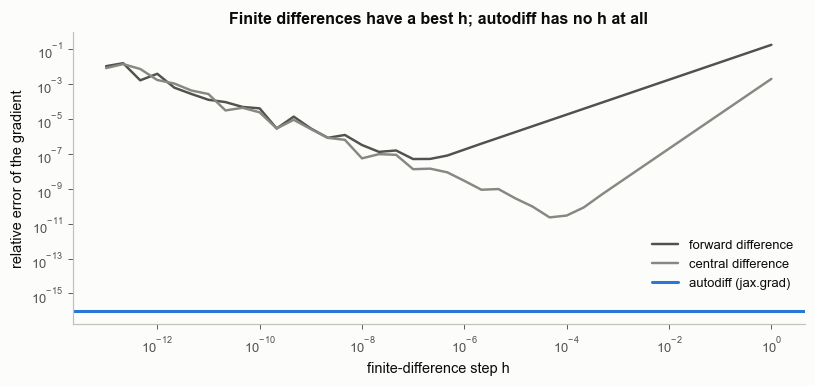

autodiff relative error vs the hand-derived gradient: 0.0e+00  (identical in float64; plotted at 1e-16)
best forward difference: 5.1e-08 at h = 1e-07;  best central difference: 2.3e-11 at h = 5e-05


In [3]:
sd = P.screw_dislocation()
m = np.array([20.0, 35.0])                                    # (D km, s mm/yr)


def grad_by_hand(m):
    D_, s_ = m
    x = sd.stations_km
    v = s_ / np.pi * np.arctan(x / D_)
    dv_ds = np.arctan(x / D_) / np.pi
    dv_dD = -s_ * x / (np.pi * (D_ ** 2 + x ** 2))
    r = (sd.y - v) / sd.sigma ** 2
    return np.array([np.sum(r * dv_dD), np.sum(r * dv_ds)]) - (m - np.array([15.0, 30.0])) / np.array([15.0, 20.0]) ** 2


g_true = grad_by_hand(m)
g_auto = sd.grad(m)
err_auto = np.abs(g_auto - g_true).max() / np.abs(g_true).max()
hs = np.logspace(-13, 0, 40)
err_fwd, err_ctr = [], []
for h in hs:
    fd = np.array([(sd.logp(m + h * e) - sd.logp(m)) / h for e in np.eye(2)])
    cd = np.array([(sd.logp(m + h * e) - sd.logp(m - h * e)) / (2 * h) for e in np.eye(2)])
    err_fwd.append(np.abs(fd - g_true).max() / np.abs(g_true).max())
    err_ctr.append(np.abs(cd - g_true).max() / np.abs(g_true).max())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.loglog(hs, err_fwd, color=S.INK2, lw=1.6, label="forward difference")
ax.loglog(hs, err_ctr, color=S.MUTED, lw=1.6, label="central difference")
ax.axhline(max(err_auto, 1e-16), color=S.COLORS["grad"], lw=2.0, label="autodiff (jax.grad)")
ax.set_xlabel("finite-difference step h"); ax.set_ylabel("relative error of the gradient")
ax.set_title("Finite differences have a best h; autodiff has no h at all")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.08))
fig.tight_layout()
bk.savefig(fig, "2-17_fd_vs_autodiff")
plt.show()
print(f"autodiff relative error vs the hand-derived gradient: {err_auto:.1e}"
      + ("  (identical in float64; plotted at 1e-16)" if err_auto < 1e-16 else ""))
print(f"best forward difference: {min(err_fwd):.1e} at h = {hs[np.argmin(err_fwd)]:.0e};  "
      f"best central difference: {min(err_ctr):.1e} at h = {hs[np.argmin(err_ctr)]:.0e}")

The U-shaped curves are the finite-difference dilemma: the left arm is round-off, the right arm truncation, and the
best $h$ depends on the function, so you never know it in advance. Autodiff (blue) has no step size and sits at
rounding level. Finite differences also cost one extra forward run *per parameter*; section 3 shows that autodiff
does not.

### The gradient, the Jacobian and the Hessian

**In plain words.** The **gradient** is the list of slopes of one number (here the log posterior) with respect to
each parameter: which way, and how steeply, the number rises. The **Jacobian** does the same for a forward model,
which returns many numbers (one prediction per datum): it is a table with one row per datum and one column per
parameter, and each column says how *all* the predictions change when that one parameter is nudged. The
**Hessian** is the table of second derivatives of one number: how the slopes themselves change, that is, the
curvature.

**Precisely.** For a forward model $\mathbf g(\mathbf m)$ with $N_d$ outputs and $N_m$ parameters,
$J_{ij} = \partial g_i/\partial m_j$ ($N_d \times N_m$). Near a point $\mathbf m_0$, $\mathbf g(\mathbf m) \approx
\mathbf g(\mathbf m_0) + \mathbf J(\mathbf m - \mathbf m_0)$: the Jacobian is the slope of the forward model, and this
straight-line approximation is the **linearisation** (2.25). For a linear model $\mathbf g = \mathbf G\mathbf m$ the
Jacobian is $\mathbf G$ itself. The gradient of the Gaussian misfit $\tfrac12\mathbf r^\top\mathbf C_d^{-1}\mathbf r$ with
$\mathbf r = \mathbf d - \mathbf g(\mathbf m)$ is $-\mathbf J^\top\mathbf C_d^{-1}\mathbf r$: the transpose sends the
weighted residuals back to the parameters (2.06, section 2). The Hessian of $-\log p$ at the peak is the inverse of
the Laplace covariance (2.08); Gauss-Newton (2.10) approximates it by $\mathbf J^\top\mathbf C_d^{-1}\mathbf J$ plus the
prior term. (The "Jacobian" of a change of variables in 2.11 is the same object for a transform $\mathbf y =
\mathbf h(\mathbf x)$; the absolute value of its determinant rescales densities.)

**Why it matters.** Every gradient-based method uses $\mathbf J$ or products with it: Gauss-Newton and
Levenberg-Marquardt (2.10), the EKF (2.25), adjoints (2.22). Below: the Jacobian of the locking-depth model at
$D$ = 20 km, $s$ = 35 mm/yr, from `jax.jacfwd`.

Jacobian at the 5 stations (rows: stations; columns: dv/dD in mm/yr per km, dv/ds per mm/yr):
[[-0.2785  0.25  ]
 [-0.2571  0.3128]
 [-0.2067  0.3669]
 [-0.1566  0.405 ]
 [-0.118   0.4304]]
max |jax.jacfwd - hand formula| = 5.6e-17


saved figures/2-17_jacobian.png


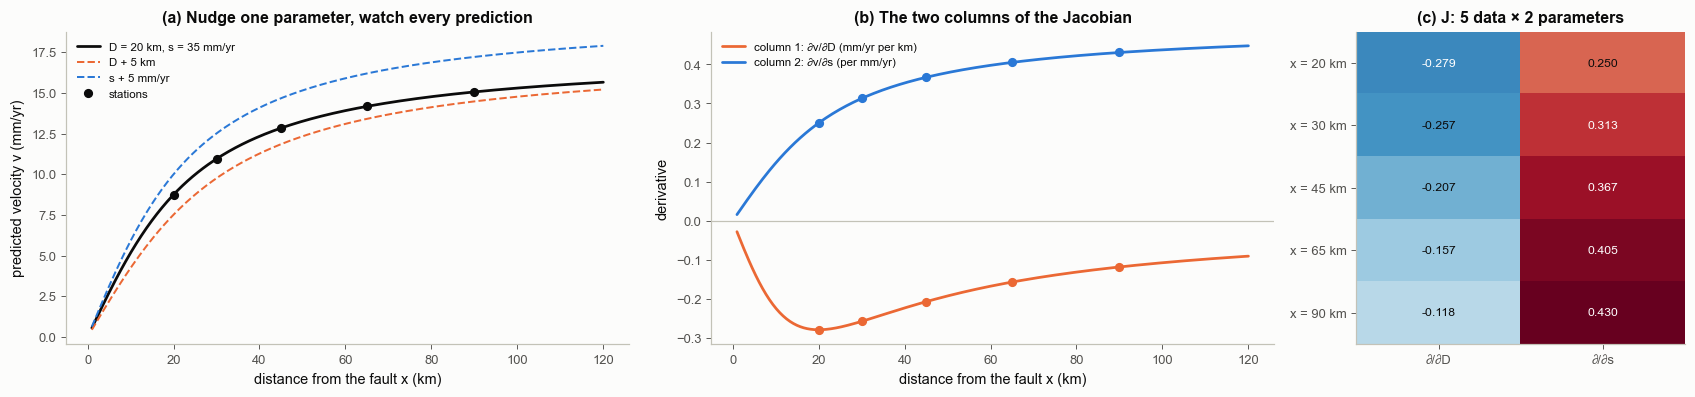

In [4]:
x_dense = np.linspace(1, 120, 300)
fwd_ld = lambda mm, x: mm[1] / np.pi * jnp.arctan(x / mm[0])            # v(x) = s/pi arctan(x/D)
J_ld = np.asarray(jax.jacfwd(lambda mm: fwd_ld(mm, jnp.asarray(sd.stations_km)))(jnp.asarray(m)))
J_dense = np.asarray(jax.jacfwd(lambda mm: fwd_ld(mm, jnp.asarray(x_dense)))(jnp.asarray(m)))
xs_ = sd.stations_km
J_hand = np.column_stack([-m[1] * xs_ / (np.pi * (m[0] ** 2 + xs_ ** 2)), np.arctan(xs_ / m[0]) / np.pi])
print("Jacobian at the 5 stations (rows: stations; columns: dv/dD in mm/yr per km, dv/ds per mm/yr):")
print(np.array2string(J_ld, precision=4))
print(f"max |jax.jacfwd - hand formula| = {np.abs(J_ld - J_hand).max():.1e}")

fig, axs = plt.subplots(1, 3, figsize=(15.5, 3.7), gridspec_kw=dict(width_ratios=[1.2, 1.2, 0.7]))
ax = axs[0]
ax.plot(x_dense, fwd_ld(m, x_dense), color=S.INK, lw=1.8, label=f"D = {m[0]:g} km, s = {m[1]:g} mm/yr")
ax.plot(x_dense, fwd_ld(m + np.array([5.0, 0.0]), x_dense), color=S.ORANGE, lw=1.3, ls="--", label="D + 5 km")
ax.plot(x_dense, fwd_ld(m + np.array([0.0, 5.0]), x_dense), color=S.BLUE, lw=1.3, ls="--", label="s + 5 mm/yr")
ax.plot(xs_, fwd_ld(m, xs_), "o", color=S.INK, ms=5, label="stations")
ax.set_xlabel("distance from the fault x (km)"); ax.set_ylabel("predicted velocity v (mm/yr)")
ax.set_title("(a) Nudge one parameter, watch every prediction"); ax.legend(fontsize=7.5)
ax = axs[1]
ax.plot(x_dense, J_dense[:, 0], color=S.ORANGE, lw=1.8, label="column 1: ∂v/∂D (mm/yr per km)")
ax.plot(x_dense, J_dense[:, 1], color=S.BLUE, lw=1.8, label="column 2: ∂v/∂s (per mm/yr)")
ax.plot(xs_, J_ld[:, 0], "o", color=S.ORANGE, ms=5); ax.plot(xs_, J_ld[:, 1], "o", color=S.BLUE, ms=5)
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("distance from the fault x (km)"); ax.set_ylabel("derivative")
ax.set_title("(b) The two columns of the Jacobian"); ax.legend(fontsize=7.5)
ax = axs[2]
lim = np.abs(J_ld).max()
im = ax.imshow(J_ld, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(J_ld.shape[0]):
    for j in range(2):
        ax.text(j, i, f"{J_ld[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if abs(J_ld[i, j]) > 0.6 * lim else S.INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["∂/∂D", "∂/∂s"])
ax.set_yticks(range(len(xs_))); ax.set_yticklabels([f"x = {x:g} km" for x in xs_])
ax.set_title("(c) J: 5 data × 2 parameters")
fig.tight_layout()
bk.savefig(fig, "2-17_jacobian")
plt.show()

**How to read it.** (a) Deepening the locking depth $D$ lowers the velocities near the fault and changes them little
far away; raising the slip rate $s$ scales the whole curve. (b) The two columns of $\mathbf J$ are exactly those changes
per unit nudge, as functions of distance; the dots are the five stations. (c) The Jacobian at the stations is the 5 × 2
table of those numbers (printed above, and equal to the hand formula to rounding). Far from the fault one column is
nearly a multiple of the other, so a change of $D$ can be compensated by a change of $s$: that is the trade-off
between them seen in the posterior of 2.02, read off the Jacobian.

## 3. How reverse-mode autodiff works, and what it costs

Take one station of the locking-depth problem and the misfit $f = r^2/(2\sigma^2)$ with $r = y - \tfrac{s}{\pi}\arctan(x/D)$.
JAX breaks it into elementary steps (**forward pass**, black values), then walks the same graph backwards
multiplying local derivatives (**backward pass**, blue values $\bar u = \partial f/\partial u$, called *adjoints*).
One backward sweep delivers the derivative with respect to **every** input at once.

saved figures/2-17_reverse_mode_graph.png


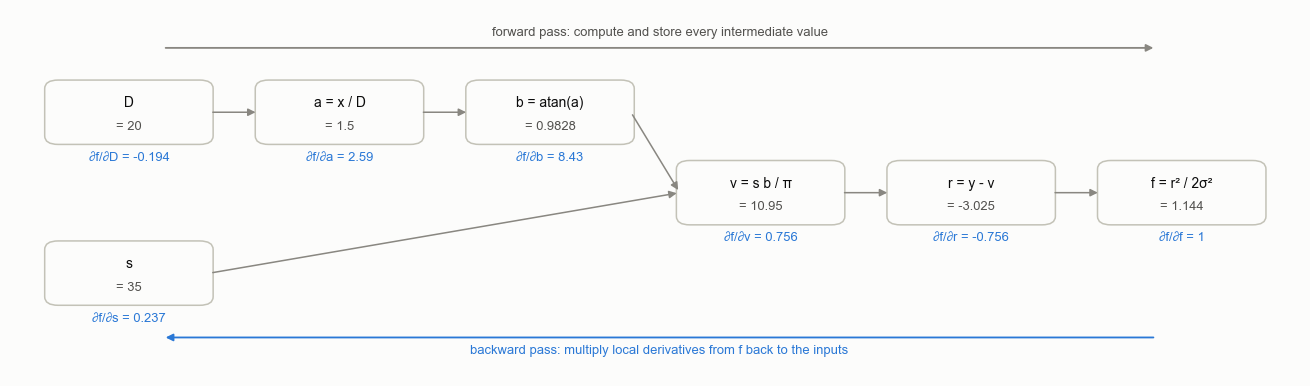

backward pass by hand: df/dD = -0.194454, df/ds = 0.236610
jax.grad:              df/dD = -0.194454, df/ds = 0.236610


In [5]:
xst, yst, sst = 30.0, float(sd.y[1]), 2.0
D0, s0 = 20.0, 35.0
a = xst / D0; b = np.arctan(a); v = s0 * b / np.pi; r = yst - v; fval = r ** 2 / (2 * sst ** 2)
f_bar = 1.0; r_bar = r / sst ** 2; v_bar = -r_bar; b_bar = v_bar * s0 / np.pi; s_bar = v_bar * b / np.pi
a_bar = b_bar / (1 + a ** 2); D_bar = a_bar * (-xst / D0 ** 2)
g_jax = jax.grad(lambda z: (yst - z[1] / jnp.pi * jnp.arctan(xst / z[0])) ** 2 / (2 * sst ** 2))(jnp.array([D0, s0]))

nodes = {  # name: (x, y, formula, forward value, adjoint)
    "D": (0.0, 0.75, "D", D0, D_bar), "s": (0.0, -0.75, "s", s0, s_bar),
    "a": (1.25, 0.75, "a = x / D", a, a_bar), "b": (2.5, 0.75, "b = atan(a)", b, b_bar),
    "v": (3.75, 0.0, "v = s b / π", v, v_bar), "r": (5.0, 0.0, "r = y - v", r, r_bar),
    "f": (6.25, 0.0, "f = r² / 2σ²", fval, f_bar)}
edges = [("D", "a"), ("a", "b"), ("b", "v"), ("s", "v"), ("v", "r"), ("r", "f")]
fig, ax = plt.subplots(figsize=(12, 3.6))
for name, (px, py, txt, val, adj) in nodes.items():
    ax.add_patch(FancyBboxPatch((px - 0.48, py - 0.28), 0.96, 0.56, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=S.SURFACE, ec=S.AXIS, lw=1.0))
    ax.text(px, py + 0.09, txt, ha="center", va="center", fontsize=9, color=S.INK)
    ax.text(px, py - 0.13, f"= {val:.4g}", ha="center", va="center", fontsize=8.5, color=S.INK2)
    ax.text(px, py - 0.42, f"∂f/∂{name} = {adj:.3g}", ha="center", va="center", fontsize=8.5, color=S.COLORS["grad"])
for u, w in edges:
    (x1, y1), (x2, y2) = nodes[u][:2], nodes[w][:2]
    ax.add_patch(FancyArrowPatch((x1 + 0.48, y1), (x2 - 0.48, y2), arrowstyle="-|>", mutation_scale=10, color=S.MUTED,
                                 lw=1.0, shrinkA=2, shrinkB=2))
ax.annotate("", xy=(0.2, -1.35), xytext=(6.1, -1.35),
            arrowprops=dict(arrowstyle="-|>", color=S.COLORS["grad"], lw=1.2))
ax.text(3.15, -1.5, "backward pass: multiply local derivatives from f back to the inputs", ha="center",
        fontsize=8.5, color=S.COLORS["grad"])
ax.annotate("", xy=(6.1, 1.35), xytext=(0.2, 1.35), arrowprops=dict(arrowstyle="-|>", color=S.MUTED, lw=1.2))
ax.text(3.15, 1.47, "forward pass: compute and store every intermediate value", ha="center", fontsize=8.5,
        color=S.INK2)
ax.set_xlim(-0.7, 6.95); ax.set_ylim(-1.7, 1.7); ax.axis("off")
fig.tight_layout()
bk.savefig(fig, "2-17_reverse_mode_graph")
plt.show()
print(f"backward pass by hand: df/dD = {D_bar:.6f}, df/ds = {s_bar:.6f}")
print(f"jax.grad:              df/dD = {float(g_jax[0]):.6f}, df/ds = {float(g_jax[1]):.6f}")

Because one backward sweep gives all derivatives, the cost of a full gradient is a small multiple of one function
evaluation **no matter how many parameters there are** (reverse mode). Forward mode (`jax.jacfwd`) instead pushes one
direction at a time and costs grow with the number of parameters, like finite differences. Timing a linear-Gaussian
log posterior $-\tfrac12\|\mathbf y - \mathbf G\mathbf m\|^2 - \tfrac12\|\mathbf m\|^2$ with 500 data and $d$ unknowns
(all compiled with `jit`):

saved figures/2-17_gradient_cost.png


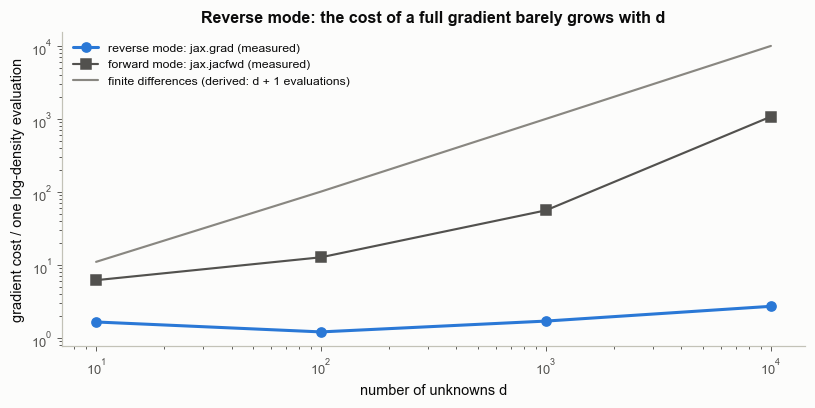

      d    f (us)  grad (us)  grad/f  jacfwd/f
     10       3.4        5.7    1.65       6.2
    100      18.7       22.5    1.21      12.7
   1000      59.4      100.8    1.70      55.9
  10000     313.9      848.9    2.70    1075.0


In [6]:
def timed(fn, x, number):
    fn(x).block_until_ready()
    return min(timeit.repeat(lambda: fn(x).block_until_ready(), number=number, repeat=3)) / number


dims, t_f, t_g, t_fwd = [10, 100, 1000, 10000], [], [], []
for dd in dims:
    G = jnp.asarray(rng.standard_normal((500, dd)) / np.sqrt(dd))
    y = jnp.asarray(rng.standard_normal(500))
    lp = lambda mm, G=G, y=y: -0.5 * jnp.sum((y - G @ mm) ** 2) - 0.5 * jnp.sum(mm ** 2)
    x0 = jnp.zeros(dd)
    t_f.append(timed(jax.jit(lp), x0, 200))
    t_g.append(timed(jax.jit(jax.grad(lp)), x0, 200))
    t_fwd.append(timed(jax.jit(jax.jacfwd(lp)), x0, 3 if dd >= 10000 else 20))
t_f, t_g, t_fwd = map(np.array, (t_f, t_g, t_fwd))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.loglog(dims, t_g / t_f, "o-", color=S.COLORS["grad"], lw=2, label="reverse mode: jax.grad (measured)")
ax.loglog(dims, t_fwd / t_f, "s-", color=S.INK2, lw=1.4, label="forward mode: jax.jacfwd (measured)")
ax.loglog(dims, np.array(dims) + 1.0, color=S.MUTED, lw=1.4, label="finite differences (derived: d + 1 evaluations)")
ax.set_xlabel("number of unknowns d"); ax.set_ylabel("gradient cost / one log-density evaluation")
ax.set_title("Reverse mode: the cost of a full gradient barely grows with d")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-17_gradient_cost")
plt.show()
print(f"{'d':>7s} {'f (us)':>9s} {'grad (us)':>10s} {'grad/f':>7s} {'jacfwd/f':>9s}")
for dd, a_, b_, c_ in zip(dims, t_f, t_g, t_fwd):
    print(f"{dd:7d} {a_ * 1e6:9.1f} {b_ * 1e6:10.1f} {b_ / a_:7.2f} {c_ / a_:9.1f}")

Read the table: the reverse-mode ratio stays within a small factor over three orders of magnitude in $d$, while
forward mode and finite differences grow roughly in proportion to $d$. **This is why NUTS on a slip model with
hundreds of patches is affordable**: each leapfrog step costs a small multiple of one forward-model evaluation (the
ratio in the table), not the $d + 1$ evaluations that one-sided finite differences would need.

## 4. `jit` and `vmap`: speed and ensembles

`jit` compiles a whole function once; afterwards a call skips Python entirely. `vmap` turns a function written for
*one* parameter vector into one that takes a whole *batch*. Example: the epicentre forward model (distances to two
stations) for an ensemble of 1000 members, the job EnKI does every iteration.

In [7]:
prob_loc = P.location(kind="bimodal")
fwd1 = prob_loc.forward_fn                                    # written for one member, m of shape (2,)
ens = jnp.asarray(rng.normal(0, 1, (1000, 2)))

t_loop = min(timeit.repeat(lambda: [fwd1(mm) for mm in ens][-1].block_until_ready(), number=1, repeat=3))
fwd_batch = jax.jit(jax.vmap(fwd1))
fwd_batch(ens).block_until_ready()
t_vmap = min(timeit.repeat(lambda: fwd_batch(ens).block_until_ready(), number=100, repeat=3)) / 100
print(f"Python loop over 1000 members (no jit): {t_loop * 1e3:8.2f} ms")
print(f"jit(vmap(forward)) on all 1000 at once: {t_vmap * 1e3:8.3f} ms   ({t_loop / t_vmap:.0f}x faster)")
print("same numbers?", bool(np.allclose(np.array([fwd1(mm) for mm in ens[:5]]), fwd_batch(ens)[:5])))

Python loop over 1000 members (no jit):    52.45 ms
jit(vmap(forward)) on all 1000 at once:    0.003 ms   (16325x faster)
same numbers? True


`InverseProblem.forward_batch` in `bayeskit` is exactly `jax.jit(jax.vmap(forward))`. The speed-up printed above is
typical: most of the loop's time is Python overhead per call, which `jit` removes and `vmap` amortises.

## 5. What "differentiable" means, in pictures

A function is differentiable where it has a well-defined slope. JAX will return *a* number for the gradient of
almost anything; it never warns you when that number is meaningless. Top row: seven functions. Bottom row: what
`jax.grad` returns for each.

saved figures/2-17_what_differentiable_means.png


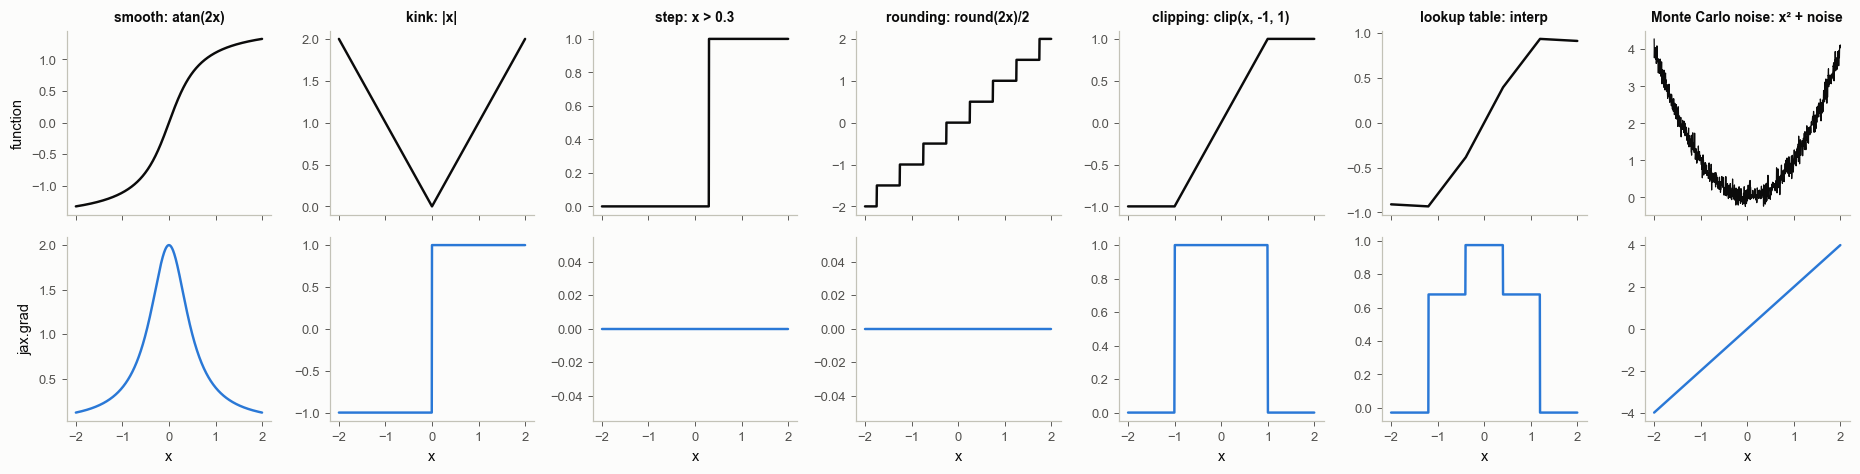

jax.grad(|x|) at 0 = 1.0   (the slope is undefined there; JAX picks a value)
jax.grad(round) at 0.3 = 0.0   jax.grad(clip) at 1.5 = 0.0


In [8]:
xx = jnp.linspace(-2, 2, 801)
xp = np.linspace(-2, 2, 6)
fp = np.sin(xp)
keys = jax.random.split(jax.random.PRNGKey(0), xx.size)
funcs = [
    ("smooth: atan(2x)", lambda t: jnp.arctan(2 * t)),
    ("kink: |x|", lambda t: jnp.abs(t)),
    ("step: x > 0.3", lambda t: jnp.where(t > 0.3, 1.0, 0.0)),
    ("rounding: round(2x)/2", lambda t: jnp.round(2 * t) / 2),
    ("clipping: clip(x, -1, 1)", lambda t: jnp.clip(t, -1, 1)),
    ("lookup table: interp", lambda t: jnp.interp(t, jnp.asarray(xp), jnp.asarray(fp))),
]
fig, axs = plt.subplots(2, 7, figsize=(17, 4.4), sharex=True)
for k, (name, fn) in enumerate(funcs):
    axs[0, k].plot(xx, jax.vmap(fn)(xx), color=S.INK, lw=1.6)
    axs[1, k].plot(xx, jax.vmap(jax.grad(fn))(xx), color=S.COLORS["grad"], lw=1.6)
    axs[0, k].set_title(name, fontsize=9)
noisy = lambda t, key: t ** 2 + 0.15 * jax.random.normal(key)        # a stochastic forward model
axs[0, 6].plot(xx, jax.vmap(noisy)(xx, keys), color=S.INK, lw=0.8)
axs[1, 6].plot(xx, jax.vmap(jax.grad(noisy))(xx, keys), color=S.COLORS["grad"], lw=1.6)
axs[0, 6].set_title("Monte Carlo noise: x² + noise", fontsize=9)
axs[0, 0].set_ylabel("function"); axs[1, 0].set_ylabel("jax.grad")
for ax in axs[1]:
    ax.set_xlabel("x")
fig.tight_layout()
bk.savefig(fig, "2-17_what_differentiable_means")
plt.show()
print("jax.grad(|x|) at 0 =", float(jax.grad(jnp.abs)(0.0)), "  (the slope is undefined there; JAX picks a value)")
print("jax.grad(round) at 0.3 =", float(jax.grad(jnp.round)(0.3)), "  jax.grad(clip) at 1.5 =",
      float(jax.grad(lambda t: jnp.clip(t, -1, 1))(1.5)))

* **Smooth**: the gradient is informative everywhere. This is what HMC/NUTS need.
* **Kink**: the slope jumps; at the kink JAX silently picks one side (printed above). Occasional kinks are survivable.
* **Step and rounding**: the gradient is **zero almost everywhere** and the jumps are invisible to it. The gradient
  says "flat" while the function changes. This is the dangerous case.
* **Clipping**: zero gradient outside the clip range, so nothing pushes back from outside.
* **Lookup table** (linear interpolation): the function is continuous but the slope is piecewise constant and jumps at
  every table node.
* **Monte Carlo noise**: every call returns a different value, so there is no single surface to differentiate. The
  gradient of each call looks fine (it ignores the noise), but the function it belongs to changes between calls.

## 6. Gradient samplers need a smooth log posterior

Make the locking-depth forward model round its predicted velocities to the nearest 0.5 mm/yr (the kind of thing that
sneaks in through a lookup table, an integer sample index or a rounded time). The posterior hardly changes, since
0.5 mm/yr is small next to the 2 mm/yr noise. But the likelihood is now made of flat terraces, and its gradient is
exactly zero.

In [9]:
xj, yj, sj = jnp.asarray(sd.stations_km), jnp.asarray(sd.y), jnp.asarray(sd.sigma)
m0p, sdp = jnp.array([15.0, 30.0]), jnp.array([15.0, 20.0])


def make_logp(q=None):
    def logp(m):
        v = m[1] / jnp.pi * jnp.arctan(xj / jnp.maximum(m[0], 1e-3))
        if q:
            v = jnp.round(v / q) * q                          # predictions rounded to q mm/yr
        lp = -0.5 * jnp.sum(((m - m0p) / sdp) ** 2) - 0.5 * jnp.sum(((yj - v) / sj) ** 2)
        return jnp.where(m[0] > 0, lp, -jnp.inf)
    return logp


smooth_t = P.Target(make_logp(None), 2, "smooth", extent=sd.extent, labels=sd.labels)
round_t = P.Target(make_logp(0.5), 2, "rounded", extent=sd.extent, labels=sd.labels)
g_s, g_r = P.grid(smooth_t, n=300), P.grid(round_t, n=300)
print("gradient at (D, s) = (20, 35):   smooth", np.round(smooth_t.grad([20.0, 35.0]), 4),
      "   rounded", np.round(round_t.grad([20.0, 35.0]), 4))
print("gradient of the prior alone:             ", np.round(-(np.array([20.0, 35.0]) - np.array([15.0, 30.0])) /
                                                    np.array([15.0, 20.0]) ** 2, 4))
print("grid posterior mean  smooth", g_s.mean.round(2), "  rounded", g_r.mean.round(2))

gradient at (D, s) = (20, 35):   smooth [ 0.3504 -0.4547]    rounded [-0.0222 -0.0125]
gradient of the prior alone:              [-0.0222 -0.0125]
grid posterior mean  smooth [29.6  36.99]   rounded [29.58 36.98]


saved figures/2-17_rounded_surface.png


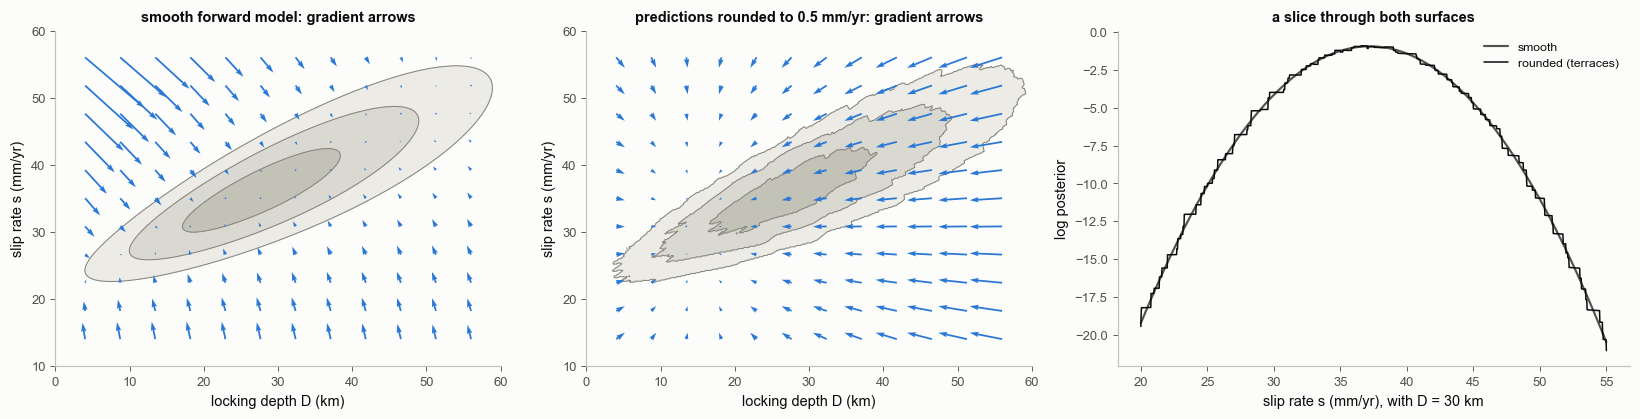

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
Dq, sq = np.meshgrid(np.linspace(4, 56, 12), np.linspace(14, 56, 11))
for ax, T, g, t in [(axs[0], smooth_t, g_s, "smooth forward model"), (axs[1], round_t, g_r, "predictions rounded to 0.5 mm/yr")]:
    BP.density(ax, g)
    G_ = np.array([T.grad([a_, b_]) for a_, b_ in zip(Dq.ravel(), sq.ravel())])
    ax.quiver(Dq.ravel(), sq.ravel(), G_[:, 0], G_[:, 1], color=S.COLORS["grad"], angles="xy", scale_units="xy",
              scale=np.percentile(np.hypot(*G_.T), 90) / 4.0, width=0.004)
    BP.frame(ax, sd)
    ax.set_title(f"{t}: gradient arrows", fontsize=9.5)
ss = np.linspace(20, 55, 1500)
lp_s = np.array([smooth_t.logp([30.0, s_]) for s_ in ss])
lp_r = np.array([round_t.logp([30.0, s_]) for s_ in ss])
axs[2].plot(ss, lp_s, color=S.INK2, lw=1.4, label="smooth")
axs[2].plot(ss, lp_r, color=S.INK, lw=1.0, label="rounded (terraces)")
axs[2].set_xlabel("slip rate s (mm/yr), with D = 30 km"); axs[2].set_ylabel("log posterior")
axs[2].set_title("a slice through both surfaces", fontsize=9.5)
axs[2].legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-17_rounded_surface")
plt.show()

In the left panel the blue arrows point towards the ridge. In the middle panel the posterior (grey regions) is almost
the same, yet the arrows (scaled separately in each panel; the rounded ones are far shorter) ignore it completely: they are the gradient of the prior alone (the numbers above match),
pointing at the prior mean (15 km, 30 mm/yr). The slice on the right shows why: on each terrace the log posterior is
flat apart from the gentle prior slope.

Now run NumPyro NUTS on both (4 chains × 1000 draws after 500 warm-up, default settings, maximum tree depth 10 =
up to 1023 leapfrog steps per draw; NUTS builds each trajectory by repeated doubling, and the **tree depth** is the
number of doublings, 2.18), and random-walk Metropolis on the rounded one.

In [11]:
def run_nuts(logp, seed=0):
    mc = MCMC(NUTS(potential_fn=lambda z: -logp(z)), num_warmup=500, num_samples=1000, num_chains=4,
              chain_method="sequential", progress_bar=False)
    init = jnp.array([[20.0, 35.0], [21.0, 34.0], [19.0, 36.0], [22.0, 37.0]])
    t0 = time.time()
    mc.run(jax.random.PRNGKey(seed), init_params=init, extra_fields=("num_steps", "diverging", "adapt_state.step_size"))
    z = np.asarray(mc.get_samples(group_by_chain=True))
    ex = mc.get_extra_fields(group_by_chain=True)
    return z, {k: np.asarray(v) for k, v in ex.items()}, time.time() - t0


z_s, ex_s, t_s = run_nuts(make_logp(None))
z_r, ex_r, t_r = run_nuts(make_logp(0.5))
rw = SM.rwm(round_t, np.tile([20.0, 35.0], (4, 1)), 10000, step=3.0, rng=np.random.default_rng(3))
z_w = rw["samples"][:, 1000:]
print(f"{'run':>24s} {'steps/draw':>10s} {'at 1023':>8s} {'step size':>10s} {'R-hat D, s':>13s} {'ESS D, s':>11s} {'time':>6s}")
for name, z, ex, tt in [("NUTS, smooth", z_s, ex_s, t_s), ("NUTS, rounded", z_r, ex_r, t_r)]:
    ns = ex["num_steps"]
    print(f"{name:>24s} {ns.mean():10.1f} {(ns >= 1023).mean():8.3f} {np.median(ex['adapt_state.step_size'][:, -1]):10.4f} "
          f"{D.rhat(z[:, :, 0]):6.3f},{D.rhat(z[:, :, 1]):6.3f} {D.ess(z[:, :, 0]):5.0f},{D.ess(z[:, :, 1]):5.0f} {tt:5.1f}s")
print(f"{'Metropolis, rounded':>24s} {'(1 eval)':>10s} {'':>8s} {'step 3.0':>10s} "
      f"{D.rhat(z_w[:, :, 0]):6.3f},{D.rhat(z_w[:, :, 1]):6.3f} {D.ess(z_w[:, :, 0]):5.0f},{D.ess(z_w[:, :, 1]):5.0f}"
      f"   acc {rw['accept_rate']:.2f}")

                     run steps/draw  at 1023  step size    R-hat D, s    ESS D, s   time
            NUTS, smooth        6.6    0.000     0.3265  1.003, 1.004   940,  955   1.8s
           NUTS, rounded     1020.8    0.995     0.0007  1.049, 1.054    51,   46   6.5s
     Metropolis, rounded   (1 eval)            step 3.0  1.013, 1.013   434,  501   acc 0.63


saved figures/2-17_nuts_on_terraces.png


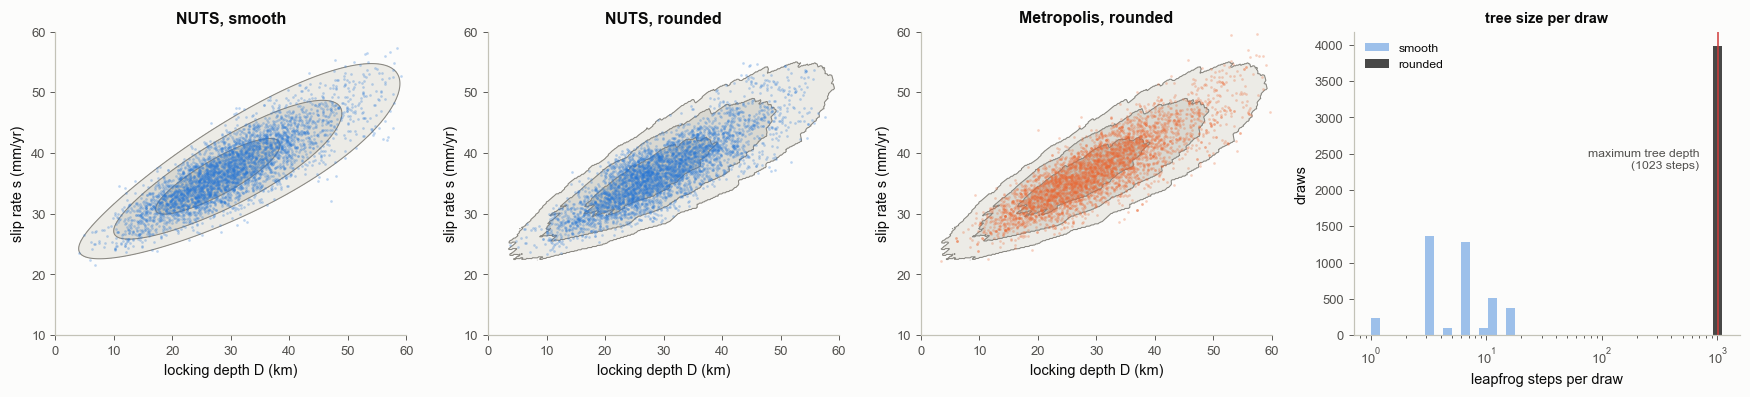

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.7), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.1]))
for ax, z, g, col, t in [(axs[0], z_s, g_s, S.COLORS["nuts"], "NUTS, smooth"), (axs[1], z_r, g_r, S.COLORS["nuts"], "NUTS, rounded"),
                         (axs[2], z_w, g_r, S.COLORS["rwm"], "Metropolis, rounded")]:
    BP.posterior_panel(ax, sd, g=g, X=z.reshape(-1, 2), color=col, title=t, s=3, alpha=0.3)
bins = np.logspace(0, np.log10(1100), 40)
axs[3].hist(ex_s["num_steps"].ravel(), bins=bins, color=S.COLORS["nuts"], alpha=0.45, label="smooth")
axs[3].hist(ex_r["num_steps"].ravel(), bins=bins, color=S.INK, alpha=0.75, label="rounded")
axs[3].axvline(1023, color=S.BAD, lw=1.0)
axs[3].text(700, axs[3].get_ylim()[1] * 0.55, "maximum tree depth\n(1023 steps)", ha="right", fontsize=8, color=S.INK2)
axs[3].set_xscale("log"); axs[3].set_xlabel("leapfrog steps per draw"); axs[3].set_ylabel("draws")
axs[3].set_title("tree size per draw", fontsize=9.5)
axs[3].legend(loc="upper left", fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-17_nuts_on_terraces")
plt.show()

**What happened** (numbers in the table above):
* On the smooth model NUTS needs a handful of leapfrog steps per draw and mixes well.
* On the rounded model the dynamics follow the prior gradient only, so the trajectory keeps walking into
  terrace edges where the energy jumps. Step-size adaptation (NUTS tunes its step during warm-up so that the
  numerical energy error stays small, 2.18) shrinks the step until those jumps are rare, the U-turn (the point where
  the trajectory starts to turn back, which ends it) is then hundreds of tiny steps away, and almost every draw hits
  the maximum tree depth ("tree depth saturation" near 1). R-hat (2.15, 2.19) and ESS (2.05) show that thousands of
  draws bought very few effective samples.
* Metropolis never looks at the gradient and samples the rounded posterior without trouble.

The accept step still uses the actual (rounded) log density, so NUTS is not sampling the *wrong* distribution here; it
is wasting its effort, and with a finite budget the result is unreliable. It is a different mechanism from a narrow
ridge, which also makes trees long but with a smooth log density (2.18). **Saturated trees with a collapsed step
size are a reason to check the log density for steps, rounding, clipping and lookups before blaming the
sampler.**

## 7. Hard bounds and transforms

Slip cannot be negative. Writing that as a hard wall (log density $-\infty$ below zero) makes the log posterior
non-smooth at the bound. One datum $d = 0.3$ m ($\sigma$ = 0.5 m) and prior slip $\sim$ HalfNormal(1 m) give a
posterior piled up against the wall. The alternative samples $u = \log s$, which has no boundary, and adds the
Jacobian $\log|ds/du| = u$ so the density is the same distribution expressed in new coordinates:

$$\log p_u(u) = \log p_s(e^u) + u.$$

saved figures/2-17_wall_vs_transform.png


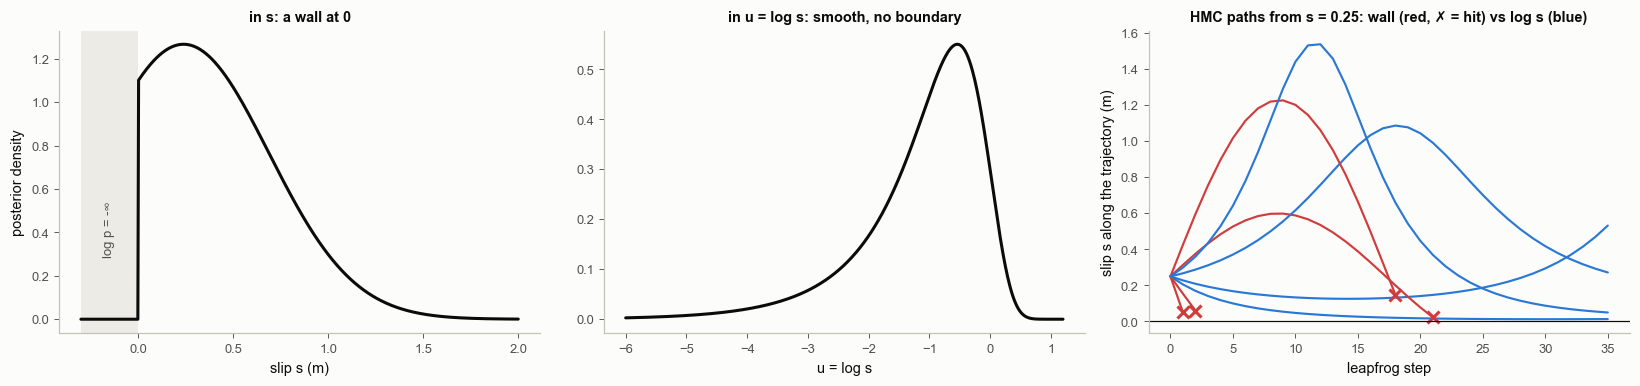

In [13]:
d1, sig1 = 0.3, 0.5
lp_wall = lambda s_: jnp.where(s_[0] >= 0, -0.5 * s_[0] ** 2 - 0.5 * ((d1 - s_[0]) / sig1) ** 2, -jnp.inf)
lp_log = lambda u_: -0.5 * jnp.exp(u_[0]) ** 2 - 0.5 * ((d1 - jnp.exp(u_[0])) / sig1) ** 2 + u_[0]
T_wall, T_log = P.Target(lp_wall, 1, "wall"), P.Target(lp_log, 1, "log")
prec = 1 + 1 / sig1 ** 2
mu_t, sd_t = (d1 / sig1 ** 2) / prec, 1 / np.sqrt(prec)
from scipy.stats import truncnorm
exact = truncnorm((0 - mu_t) / sd_t, np.inf, loc=mu_t, scale=sd_t)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
s_grid = np.linspace(-0.3, 2.0, 600)
axs[0].plot(s_grid, exact.pdf(s_grid), color=S.INK, lw=2)
axs[0].axvspan(-0.3, 0, color="#ecebe6", lw=0)
axs[0].text(-0.15, 0.3, "log p = -∞", rotation=90, ha="center", fontsize=8.5, color=S.INK2)
axs[0].set_xlabel("slip s (m)"); axs[0].set_ylabel("posterior density")
axs[0].set_title("in s: a wall at 0", fontsize=9.5)
u_grid = np.linspace(-6, 1.2, 600)
pu = exact.pdf(np.exp(u_grid)) * np.exp(u_grid)
axs[1].plot(u_grid, pu, color=S.INK, lw=2)
axs[1].set_xlabel("u = log s"); axs[1].set_title("in u = log s: smooth, no boundary", fontsize=9.5)
for k, p0 in enumerate([-2.5, -1.2, 0.8, 2.2]):              # same starting slip, four momenta
    _, _, _, _, path = SM.leapfrog(T_wall, np.array([0.25]), np.array([p0]), T_wall.grad([0.25]), 0.08, 35,
                                   np.eye(1), record=True)
    hit = len(path) < 36
    axs[2].plot(np.arange(len(path)), path[:, 0], color=S.BAD if hit else S.MUTED, lw=1.4)
    if hit:
        axs[2].plot(len(path) - 1, path[-1, 0], "x", color=S.BAD, ms=8, mew=2)
    _, _, _, _, pu_path = SM.leapfrog(T_log, np.array([np.log(0.25)]), np.array([p0]),
                                      T_log.grad([np.log(0.25)]), 0.08, 35, np.eye(1), record=True)
    axs[2].plot(np.arange(len(pu_path)), np.exp(pu_path[:, 0]), color=S.COLORS["grad"], lw=1.4)
axs[2].axhline(0, color=S.INK, lw=0.8)
axs[2].set_xlabel("leapfrog step"); axs[2].set_ylabel("slip s along the trajectory (m)")
axs[2].set_title("HMC paths from s = 0.25: wall (red, ✗ = hit) vs log s (blue)", fontsize=9.5)
fig.tight_layout()
bk.savefig(fig, "2-17_wall_vs_transform")
plt.show()

Trajectories in $s$ that reach zero step into the $-\infty$ region and must be thrown away (red). In $u = \log s$ the
same trajectories bend away from zero smoothly, because approaching $s = 0$ means $u \to -\infty$ and the Jacobian
term $+u$ pushes back. How much this costs, with long-run samplers (exact answer: the truncated Gaussian):

In [14]:
rows = []
for label, T, x0, back, kw in [
        ("HMC fixed L, wall", T_wall, [0.3], lambda c: c, dict(eps=0.3, L=10)),
        ("HMC random L, wall", T_wall, [0.3], lambda c: c, dict(eps=0.3, L=10, jitter_L=True)),
        ("HMC fixed L, log s", T_log, [np.log(0.3)], np.exp, dict(eps=0.3, L=10))]:
    r_ = SM.hmc(T, np.array(x0), 20000, rng=np.random.default_rng(0), **kw)
    s_ = back(r_["chain"][:, 0])
    rows.append((label, r_["accept_rate"], np.nan, s_.mean(), s_.std(), D.ess(s_), s_.max()))
nuts_samples = {}
for label, T, x0, back in [("NUTS, wall", T_wall, [0.3], lambda c: c), ("NUTS, log s", T_log, [np.log(0.3)], np.exp)]:
    r_ = SM.nuts(T, np.array(x0), 5000, n_warmup=1000, rng=np.random.default_rng(2))
    s_ = back(r_["chain"][:, 0])
    nuts_samples[label] = s_
    rows.append((label, r_["accept_stat"][1000:].mean(), r_["divergent"][1000:].mean(), s_.mean(), s_.std(), D.ess(s_), s_.max()))
print(f"exact posterior: mean {exact.mean():.3f}, sd {exact.std():.3f}")
print(f"{'sampler':>20s} {'accept':>7s} {'divergent':>10s} {'mean':>7s} {'sd':>7s} {'ESS':>7s} {'max s':>6s}")
for lab, acc, dv, mu_, sdv, es, mx in rows:
    dvs = "" if np.isnan(dv) else f"{dv:.3f}"
    print(f"{lab:>20s} {acc:7.3f} {dvs:>10s} {mu_:7.3f} {sdv:7.3f} {es:7.0f} {mx:6.2f}")

exact posterior: mean 0.459, sd 0.315
             sampler  accept  divergent    mean      sd     ESS  max s
   HMC fixed L, wall   0.308              0.250   0.141     330   0.49
  HMC random L, wall   0.293              0.453   0.312    1037   2.08
  HMC fixed L, log s   0.976              0.456   0.312   26390   2.10
          NUTS, wall   0.837      0.411   0.456   0.302     855   1.77
         NUTS, log s   0.776      0.002   0.462   0.311    1142   1.82


Three lessons from the table:
* **Fixed-length HMC against a wall can be badly wrong.** Each trajectory here lasts about one oscillation of the
  bowl, so any swing large enough to travel far also swings into the wall and is rejected. The chain never leaves
  the neighbourhood of the mode (compare its maximum and its mean with the exact values).
* Randomising the trajectory length restores the right answer, at a cost in acceptance and ESS.
* **NUTS stays correct but reports the wall as divergences** (trajectories whose energy error blew up, 2.18; the
  fraction printed), and its adapted step size
  shrinks. Divergences that cluster at a parameter bound are the classic sign of an untransformed constraint. In
  $\log s$ the same NUTS has almost none.

NumPyro does this transform for you: every constrained distribution is sampled in unconstrained coordinates with the
Jacobian added automatically.

In [15]:
from numpyro.distributions.transforms import biject_to
def describe(tr):
    parts = getattr(tr, "parts", [tr])
    return " then ".join(type(t).__name__ for t in parts)


print("HalfNormal(1), support", dist.HalfNormal(1.0).support, "-> NumPyro samples u and applies:", describe(biject_to(dist.HalfNormal(1.0).support)))
print("Uniform(0, 3.5), support", dist.Uniform(0.0, 3.5).support, "-> NumPyro samples u and applies:", describe(biject_to(dist.Uniform(0.0, 3.5).support)))

HalfNormal(1), support Positive(lower_bound=0.0) -> NumPyro samples u and applies: ExpTransform
Uniform(0, 3.5), support Interval(lower_bound=0.0, upper_bound=3.5) -> NumPyro samples u and applies: SigmoidTransform then AffineTransform


For a bounded interval NumPyro applies a sigmoid followed by an affine map (printed above),
$x = lb + (ub - lb)\,\mathrm{sigmoid}(\xi)$. The same map is a common way to keep ensemble Kalman members inside
bounds: the ensemble update happens in the unbounded $\xi$, so a Gaussian step can never leave the bounds (2.24).

## 8. Who needs a gradient? One banana, six methods

| method | uses the gradient? | what it returns | cost per step | typical failure |
|---|---|---|---|---|
| gradient ascent / L-BFGS (2.10) | yes | one point (the MAP) | 1 gradient | says nothing about uncertainty |
| Laplace approximation (2.08) | yes (+ Hessian) | a Gaussian at the MAP | 1 Hessian | wrong for curved or multimodal posteriors |
| HMC / NUTS | yes | samples | many gradients | non-smooth log density, funnels, separated modes |
| random-walk Metropolis | no | samples | 1 evaluation | slow in high dimension and along ridges |
| SMC (tempering, 2.20) | no (Metropolis moves) | weighted samples + evidence (normalising constant) | many evaluations | cost; needs good moves |
| EnKI (2.24) | no (ensemble means and covariances) | an ensemble | 1 forward run per member per iteration | strongly non-Gaussian posteriors, J < dimension |

gradient ascent: end point [-0. -0.]  |gradient| there 3.4e-07


saved figures/2-17_banana_six_methods.png


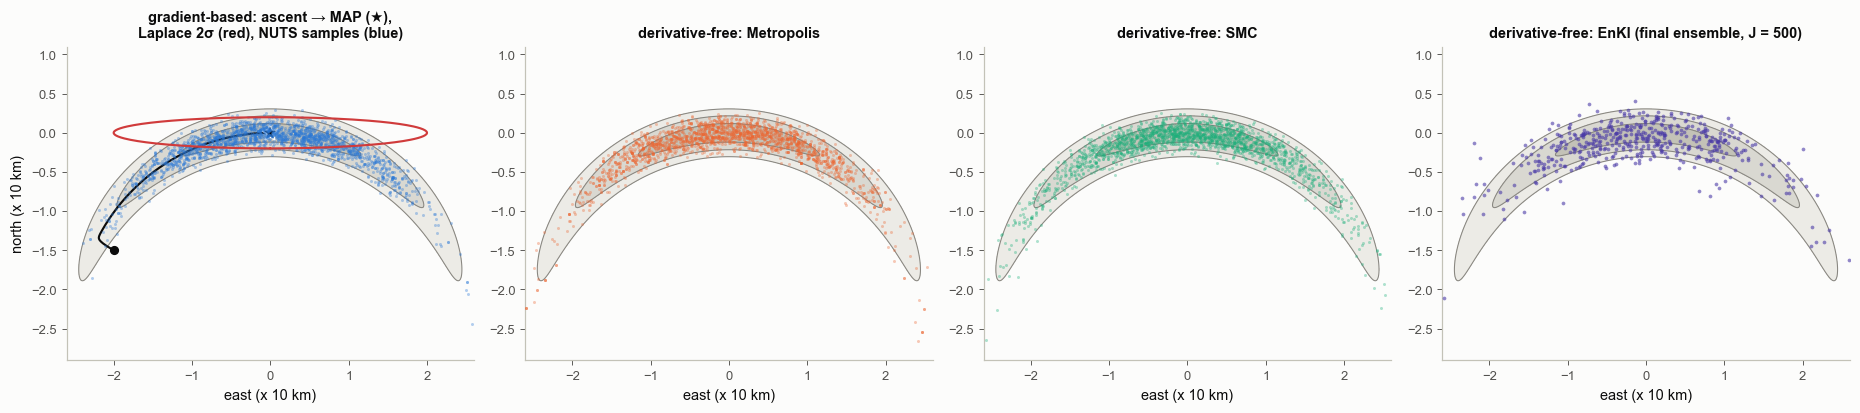

cost: NUTS 22368 gradients | Metropolis 20004 log-density evaluations | SMC 62000 evaluations | EnKI 5500 forward runs (10 iterations of J = 500)
probability inside the Laplace 2-sigma ellipse: 0.60 (0.86 if it were right)
fraction of samples inside the exact 90 % region (0.90 if the method is right):
         NUTS: 0.91
   Metropolis: 0.89
          SMC: 0.88
         EnKI: 0.69


In [16]:
ban = P.location(kind="banana")
g_b = P.grid(ban, n=450)
path = [np.array([-2.0, -1.5])]                               # plain gradient ascent with a fixed step
for _ in range(4000):
    path.append(path[-1] + 0.004 * ban.grad(path[-1]))
path = np.array(path)
m_map = path[-1]
print("gradient ascent: end point", m_map.round(4), " |gradient| there", f"{np.linalg.norm(ban.grad(m_map)):.1e}")
H = -np.asarray(jax.hessian(ban._logp_fn)(jnp.asarray(m_map)))
C_lap = np.linalg.inv(H)
ban.reset_counts()
nu = SM.nuts(ban, np.zeros(2), 2000, n_warmup=500, rng=np.random.default_rng(1))
n_nuts = ban.n_grad
ban.reset_counts()
rw_b = SM.rwm(ban, np.zeros((4, 2)), 5000, step=0.3, rng=np.random.default_rng(1))
n_rwm = ban.n_logp
ban.reset_counts()
smc_b = SM.smc(ban, n=2000, rng=np.random.default_rng(1))
n_smc = ban.n_logp
ban.reset_counts()
en_b = SM.enki(ban, J=500, rng=np.random.default_rng(1))
n_enki = ban.n_logp

fig, axs = plt.subplots(1, 4, figsize=(17, 3.9))
BP.density(axs[0], g_b)
BP.samples(axs[0], nu["chain"], S.COLORS["nuts"], s=4, alpha=0.35)
axs[0].plot(path[:, 0], path[:, 1], color=S.INK, lw=1.4)
axs[0].plot(*path[0], "o", color=S.INK, ms=5)
axs[0].plot(*m_map, "*", color=S.INK, ms=12, mec=S.SURFACE)
BP.ellipse(axs[0], m_map, C_lap, nsig=2, color=S.BAD, lw=1.4)
BP.frame(axs[0], ban, equal=True)
axs[0].set_title("gradient-based: ascent → MAP (★),\nLaplace 2σ (red), NUTS samples (blue)", fontsize=9.5)
for ax, X, col, t, kw in [(axs[1], rw_b["samples"][:, 1000:].reshape(-1, 2), S.COLORS["rwm"], "Metropolis", dict(n_max=2000)),
                          (axs[2], smc_b["samples"], S.COLORS["smc"], "SMC", dict(n_max=2000)),
                          (axs[3], en_b["samples"], S.COLORS["enki"], "EnKI (final ensemble, J = 500)", dict(n_max=500, s=6, alpha=0.6))]:
    BP.density(ax, g_b)
    BP.samples(ax, X, col, **({"s": 4, "alpha": 0.35} | kw))
    BP.frame(ax, ban, equal=True)
    ax.set_title(f"derivative-free: {t}", fontsize=9.5)
for ax in axs[1:]:
    ax.set_ylabel("")
fig.tight_layout()
bk.savefig(fig, "2-17_banana_six_methods")
plt.show()
print(f"cost: NUTS {n_nuts} gradients | Metropolis {n_rwm} log-density evaluations | SMC {n_smc} evaluations | "
      f"EnKI {n_enki} forward runs ({len(en_b['history']) - 1} iterations of J = 500)")
print(f"probability inside the Laplace 2-sigma ellipse: {g_b.mass(lambda X, Y: np.einsum('...i,ij,...j->...', np.stack([X - m_map[0], Y - m_map[1]], -1), H, np.stack([X - m_map[0], Y - m_map[1]], -1)) < 4):.2f} (0.86 if it were right)")
lev90 = g_b.levels[0.9]


def frac_in_90(X):
    """Fraction of samples that land inside the exact posterior's 90 % highest-density region (0.90 for a correct sampler)."""
    ix = np.clip(np.round((X[:, 0] - g_b.X[0, 0]) / g_b.dx).astype(int), 0, g_b.X.shape[1] - 1)
    iy = np.clip(np.round((X[:, 1] - g_b.Y[0, 0]) / g_b.dy).astype(int), 0, g_b.Y.shape[0] - 1)
    return np.mean(g_b.P[iy, ix] >= lev90)


print("fraction of samples inside the exact 90 % region (0.90 if the method is right):")
for lab, X in [("NUTS", nu["chain"]), ("Metropolis", rw_b["samples"][:, 1000:].reshape(-1, 2)), ("SMC", smc_b["samples"]),
               ("EnKI", en_b["samples"])]:
    print(f"   {lab:>10s}: {frac_in_90(X):.2f}")

Left: the optimiser (black path) climbs to the arc, crawls along it to the peak and stops; it knows nothing about the
rest of the arc. The Laplace ellipse is the Gaussian that the peak's curvature implies and misses the arms of the
banana (probability inside it printed above). NUTS uses the same gradients to *explore* and fills the arc. The
derivative-free panels: Metropolis and SMC fill the arc using only log-density values. EnKI never evaluates the log
density at all, only forward runs, and its update uses only the ensemble's means and covariances: here its members
pile up near the top of the arc and scatter off it instead of bending along it, so fewer of them land inside the
exact 90 % region (the fractions printed above; notebook 2.24 explains why). The costs printed above differ by orders of magnitude, and so
does what you get for them.

## 9. Black-box physics: where the gradient can come from

PyLith, GeoClaw or an ODE solver written in MATLAB or Fortran are not JAX code, so `jax.grad` cannot see inside
them. What matters is
whether the *inversion* has to call them.

saved figures/2-17_black_box_paths.png


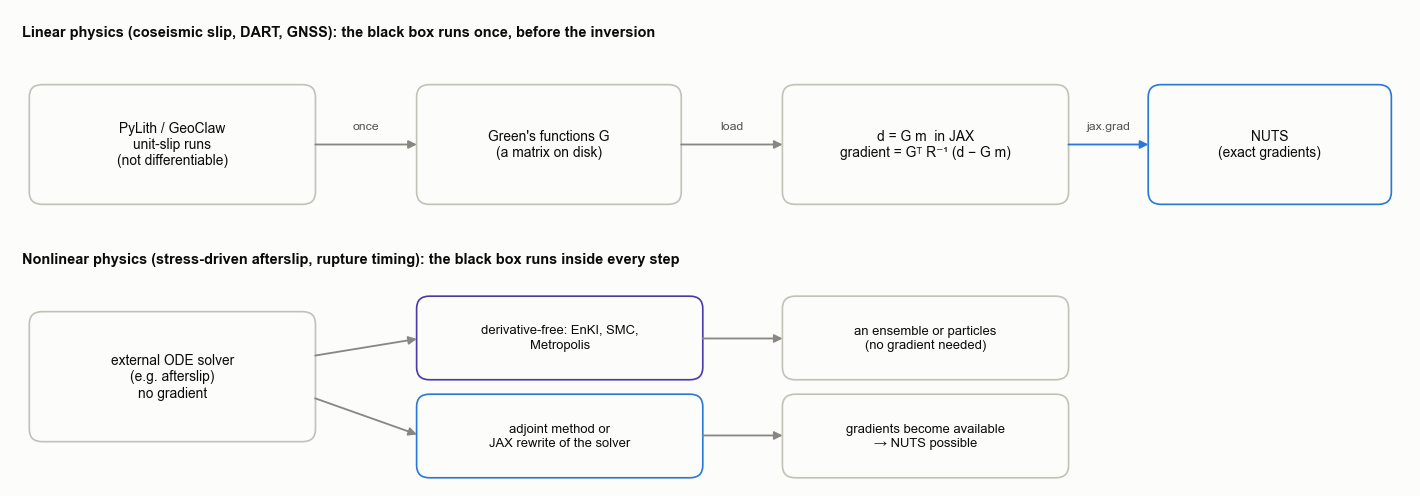

In [17]:
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 4.6)


def box(x0, y0, w, h, text, ec=S.AXIS, fc=S.SURFACE, fs=9):
    ax.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0.03,rounding_size=0.12", fc=fc, ec=ec, lw=1.1))
    ax.text(x0 + w / 2, y0 + h / 2, text, ha="center", va="center", fontsize=fs, color=S.INK)


def arrow(x1, y1, x2, y2, c=S.MUTED, text=None, dy=0.15):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=11, color=c, lw=1.2))
    if text:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + dy, text, ha="center", fontsize=8, color=S.INK2)


ax.text(0.1, 4.35, "Linear physics (coseismic slip, DART, GNSS): the black box runs once, before the inversion",
        fontsize=9.5, fontweight="bold", color=S.INK)
box(0.2, 2.75, 2.6, 1.1, "PyLith / GeoClaw\nunit-slip runs\n(not differentiable)")
box(3.8, 2.75, 2.4, 1.1, "Green's functions G\n(a matrix on disk)")
box(7.2, 2.75, 2.6, 1.1, "d = G m  in JAX\ngradient = Gᵀ R⁻¹ (d − G m)")
box(10.6, 2.75, 2.2, 1.1, "NUTS\n(exact gradients)", ec=S.COLORS["nuts"])
arrow(2.8, 3.3, 3.8, 3.3, text="once")
arrow(6.2, 3.3, 7.2, 3.3, text="load")
arrow(9.8, 3.3, 10.6, 3.3, c=S.COLORS["nuts"], text="jax.grad")
ax.text(0.1, 2.15, "Nonlinear physics (stress-driven afterslip, rupture timing): the black box runs inside every step",
        fontsize=9.5, fontweight="bold", color=S.INK)
box(0.2, 0.45, 2.6, 1.2, "external ODE solver\n(e.g. afterslip)\nno gradient")
box(3.8, 1.05, 2.6, 0.75, "derivative-free: EnKI, SMC,\nMetropolis", ec=S.COLORS["enki"], fs=8.5)
box(3.8, 0.1, 2.6, 0.75, "adjoint method or\nJAX rewrite of the solver", ec=S.COLORS["nuts"], fs=8.5)
box(7.2, 1.05, 2.6, 0.75, "an ensemble or particles\n(no gradient needed)", fs=8.5)
box(7.2, 0.1, 2.6, 0.75, "gradients become available\n→ NUTS possible", fs=8.5)
arrow(2.8, 1.25, 3.8, 1.42)
arrow(2.8, 0.85, 3.8, 0.48)
arrow(6.4, 1.42, 7.2, 1.42)
arrow(6.4, 0.48, 7.2, 0.48)
fig.tight_layout()
bk.savefig(fig, "2-17_black_box_paths")
plt.show()

A quick check of the top row: build G with a "black box" that knows nothing about JAX (plain NumPy, one unit-slip
run per column), then let `jax.grad` differentiate the inversion's log posterior.

In [18]:
z_top = np.linspace(0, 30, 16)                                # 15 depth patches of an antiplane fault (km)
x_sta = np.linspace(-62.5, 62.5, 26)                          # 26 stations (km), none on the fault trace


def black_box_forward(slip):                                   # plain NumPy: a stand-in for PyLith
    u = np.zeros(x_sta.size)
    for j, sj_ in enumerate(slip):
        u += sj_ / np.pi * (np.arctan(z_top[j + 1] / x_sta) - np.arctan(z_top[j] / x_sta))
    return u


G_bb = np.column_stack([black_box_forward(e) for e in np.eye(15)])   # one "unit-slip run" per patch
d_obs = black_box_forward(np.exp(-((z_top[:-1] - 10) / 5) ** 2)) + 0.01 * rng.standard_normal(26)
Gj, dj = jnp.asarray(G_bb), jnp.asarray(d_obs)
logpost = lambda mm: -0.5 * jnp.sum(((dj - Gj @ mm) / 0.01) ** 2) - 0.5 * jnp.sum(mm ** 2)
m_test = rng.normal(0, 0.5, 15)
g_autodiff = np.asarray(jax.grad(logpost)(jnp.asarray(m_test)))
g_formula = G_bb.T @ (d_obs - G_bb @ m_test) / 0.01 ** 2 - m_test
print("max |jax.grad - G^T R^-1 (d - G m) + prior term| =", f"{np.abs(g_autodiff - g_formula).max():.2e}",
      " (relative to the gradient size", f"{np.abs(g_formula).max():.2e})")

max |jax.grad - G^T R^-1 (d - G m) + prior term| = 1.14e-13  (relative to the gradient size 6.95e+02)


The black box was never differentiated: it ran 15 times to build $\mathbf G$, and from then on the forward model is a
matrix product that JAX differentiates exactly. That is the whole reason NUTS is practical for slip inversions. When
the physics is nonlinear and must be re-run at every step, the options are the bottom row: a derivative-free method
(EnKI, 2.24), an adjoint (a second solver that computes $\mathbf J^\top\mathbf v$ backwards in time, 2.22; JAX can wrap one
with `jax.custom_vjp`), or rewriting the solver in JAX so `jax.grad` sees through it.

## 10. CPU or GPU? (in preparation)

This section is in preparation. It will cover when a GPU speeds up an inversion (large batched forward models,
such as many ensemble members or particles evaluated at once, and big dense linear algebra) and when it does not
(small or strictly sequential work, such as the steps of a single MCMC chain), and why the choice between float32
and float64 precision matters for ill-conditioned inverse problems.

**In practice.**
* A slip inversion whose forward model is $\mathbf G\mathbf m$ with precomputed Green's functions is cheap to
  differentiate: autodiff through a linear forward model costs about as much as the forward model itself
  (section 3's table), which is what makes NUTS practical there.
* Saturated trees plus a collapsed step size are the signature of a non-smooth log density (section 6). Before
  blaming NUTS, look for rounding, integer indices, clipping, lookups or `where` switches in the forward model.
* Positivity and bounds belong in transforms, not walls (section 7). NumPyro's constrained distributions do it
  automatically; ensemble methods can use the sigmoid map.
* A nonlinear forward model that runs as a black-box solver inside every step (stress-driven afterslip, for
  instance) leaves derivative-free methods (2.24) unless an adjoint (2.22) or a differentiable rewrite of the solver
  provides gradients.

Next: [**2.18 · Gradients, HMC and NUTS**](2-18_gradients_hmc_nuts.ipynb).